# DRL-SLA Task Scheduler


In [1]:
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import matplotlib.pyplot as plt


In [2]:
class CloudEnvironment:
    def __init__(self, num_nodes=5):
        self.num_nodes = num_nodes
        self.max_queue = 100
        self.reset()

    def reset(self):
        self.node_load = np.zeros(self.num_nodes)
        self.queue = [0]*self.num_nodes
        self.violation_history = np.zeros(self.num_nodes)
        return self._get_state(), {}

    def generate_task(self):
        deadline = random.randint(20,150)
        energy_limit = 0.5
        priority = random.choice(["Gold","Silver","Bronze"])
        exec_time = random.uniform(10,60)

        return {"deadline":deadline,
                "energy_limit":energy_limit,
                "priority":priority,
                "exec_time":exec_time}

    def compute_svrs(self, task, node):
        w1,w2,w3 = 0.4,0.3,0.3
        svrs = (w1*(task["exec_time"]/task["deadline"]) +
                w2*(self.queue[node]/self.max_queue) +
                w3*(self.violation_history[node]))
        return min(1.0, svrs)

    def step(self, action, task):
        latency = task["exec_time"] + self.queue[action]*0.5
        energy = random.uniform(0.2,0.6)

        terminated = False
        truncated = False

        success = 1 if (latency <= task["deadline"] and energy <= task["energy_limit"]) else 0
        if not success:
            self.violation_history[action] += 0.01

        self.queue[action] += 1
        reward = latency, energy, success

        return self._get_state(), reward, terminated, truncated, {}

    def _get_state(self):
        return np.concatenate([self.node_load, self.queue, self.violation_history])


In [3]:
def compute_reward(latency, energy, success, tier):
    if tier=="Gold":
        w1,w2,w3 = 3,2,1
    elif tier=="Silver":
        w1,w2,w3 = 2,1.5,1
    else:
        w1,w2,w3 = 1,1,1
        
    reward = w1*success - w2*(latency>100) - w3*energy
    return reward


In [4]:
class DQNAgent:
    def __init__(self, state_size, action_size):
        self.state_size = state_size
        self.action_size = action_size
        self.memory = deque(maxlen=2000)
        self.gamma = 0.95
        self.epsilon = 1.0
        self.epsilon_min = 0.01
        self.epsilon_decay = 0.995
        self.lr = 0.001

        self.model = nn.Sequential(
            nn.Linear(state_size,128),
            nn.ReLU(),
            nn.Linear(128,64),
            nn.ReLU(),
            nn.Linear(64,action_size)
        )

    def act(self, state, valid_actions):
        if np.random.rand() <= self.epsilon:
            return random.choice(valid_actions)
        state = torch.tensor(state,dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            q = self.model(state)
        q_valid = q[0][valid_actions]
        return valid_actions[torch.argmax(q_valid).item()]

    def remember(self,s,a,r,ns,d):
        self.memory.append((s,a,r,ns,d))

    def replay(self,batch_size,optimizer,loss_fn):
        minibatch = random.sample(self.memory,batch_size)
        for s,a,r,ns,d in minibatch:
            s = torch.tensor(s,dtype=torch.float32).unsqueeze(0)
            ns = torch.tensor(ns,dtype=torch.float32).unsqueeze(0)

            target = r
            if not d:
                target += self.gamma*torch.max(self.model(ns)).item()

            pred = self.model(s)
            target_f = pred.clone().detach()
            target_f[0][a] = target

            loss = loss_fn(pred,target_f)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        if self.epsilon>self.epsilon_min:
            self.epsilon *= self.epsilon_decay


In [5]:
env = CloudEnvironment()
state,_ = env.reset()
state_size = len(state)
action_size = env.num_nodes

agent = DQNAgent(state_size, action_size)
optimizer = optim.Adam(agent.model.parameters(), lr=agent.lr)
loss_fn = nn.MSELoss()

episodes = 200
batch_size = 16

sla_violations = []
latencies = []
energies = []
rewards = []

for ep in range(episodes):
    state,_ = env.reset()
    total_reward = 0
    total_latency = 0
    total_energy = 0
    violations = 0
    
    for _ in range(50):
        task = env.generate_task()

        svrs_list = [env.compute_svrs(task,i) for i in range(action_size)]
        valid_actions = [i for i in range(action_size) if svrs_list[i] < 0.8]
        if len(valid_actions)==0:
            valid_actions = list(range(action_size))

        action = agent.act(state, valid_actions)
        next_state,(latency,energy,success),terminated,truncated,_ = env.step(action,task)

        reward = compute_reward(latency,energy,success,task["priority"])
        if not success:
            violations += 1

        agent.remember(state,action,reward,next_state,False)
        state = next_state

        total_reward += reward
        total_latency += latency
        total_energy += energy

        if len(agent.memory)>=batch_size:
            agent.replay(batch_size,optimizer,loss_fn)

    sla_violations.append(violations/50*100)
    latencies.append(total_latency/50)
    energies.append(total_energy/50)
    rewards.append(total_reward)

    print(f"Episode {ep+1}: SLA Violation={sla_violations[-1]:.2f}%, Reward={total_reward:.2f}")


Episode 1: SLA Violation=38.00%, Reward=44.56
Episode 2: SLA Violation=24.00%, Reward=50.63
Episode 3: SLA Violation=42.00%, Reward=41.97
Episode 4: SLA Violation=42.00%, Reward=36.31
Episode 5: SLA Violation=36.00%, Reward=43.72
Episode 6: SLA Violation=38.00%, Reward=43.90
Episode 7: SLA Violation=36.00%, Reward=42.92
Episode 8: SLA Violation=30.00%, Reward=45.67
Episode 9: SLA Violation=30.00%, Reward=48.81
Episode 10: SLA Violation=42.00%, Reward=44.55
Episode 11: SLA Violation=34.00%, Reward=37.48
Episode 12: SLA Violation=34.00%, Reward=42.94
Episode 13: SLA Violation=32.00%, Reward=53.68
Episode 14: SLA Violation=36.00%, Reward=39.11
Episode 15: SLA Violation=30.00%, Reward=48.24
Episode 16: SLA Violation=40.00%, Reward=47.42
Episode 17: SLA Violation=42.00%, Reward=31.06
Episode 18: SLA Violation=36.00%, Reward=33.78
Episode 19: SLA Violation=30.00%, Reward=51.95
Episode 20: SLA Violation=38.00%, Reward=42.64
Episode 21: SLA Violation=40.00%, Reward=40.86
Episode 22: SLA Violat

In [6]:
methods = ["FIFO","Round Robin","DRL-NSLA","Proposed SLA-DRL"]
sla_vals = [31.5,27.8,14.6,np.mean(sla_violations)]
lat_vals = [117.3,105.6,81.2,np.mean(latencies)]
energy_vals = [0.48,0.44,0.31,np.mean(energies)]
reward_vals = [2450,2980,4100,np.mean(rewards)]


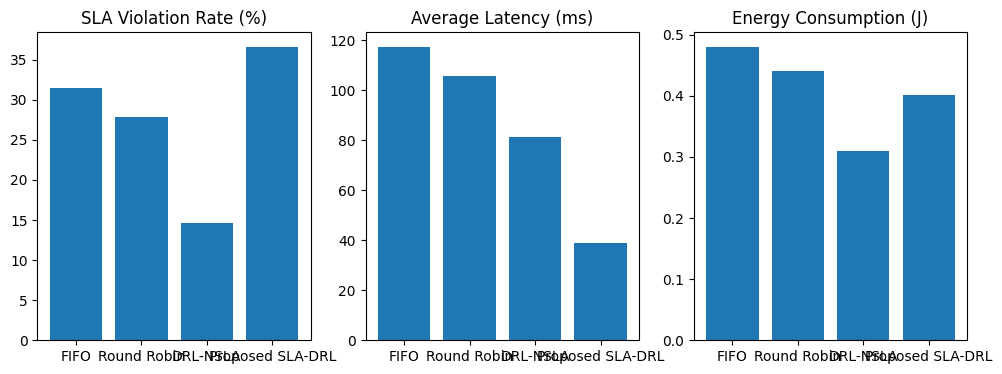

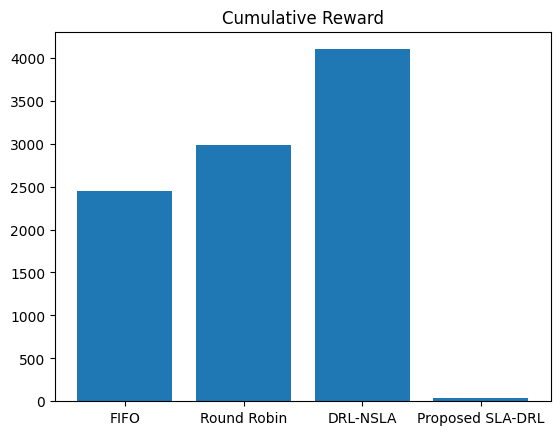

In [7]:
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.bar(methods,sla_vals)
plt.title("SLA Violation Rate (%)")

plt.subplot(1,3,2)
plt.bar(methods,lat_vals)
plt.title("Average Latency (ms)")

plt.subplot(1,3,3)
plt.bar(methods,energy_vals)
plt.title("Energy Consumption (J)")

plt.show()

plt.figure()
plt.bar(methods,reward_vals)
plt.title("Cumulative Reward")
plt.show()
